In [156]:

import gzip
import json
from pathlib import Path
from urllib.request import urlretrieve

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse

SEED = 42
DATA_DIR = Path("data") / "amazon_musical_instruments_2018"
DATA_DIR.mkdir(parents=True, exist_ok=True)


# Домашнее задание 1. Сравнение рекомендательных алгоритмов

**Цель работы:** реализовать с нуля пять рекомендательных алгоритмов и сравнить качество персональных Top-10 рекомендаций на едином датасете.

**Датасет:** Amazon Reviews 2018 — Musical Instruments (5-core).

**Источник:** [Amazon Review Data (2018)](https://cseweb.ucsd.edu/~jmcauley/datasets/amazon_v2/).

Датасет содержит пользовательские оценки музыкальных инструментов и аксессуаров, а также метаданные товаров. Взаимодействием считается отзыв пользователя о товаре с числовой оценкой от 1 до 5.

Используются следующие поля:

- `user_id` — идентификатор пользователя;
- `item_id` — идентификатор товара (ASIN);
- `rating` — оценка товара;
- `timestamp` — дата взаимодействия в формате Unix;
- `datetime` — дата в формате UTC;
- `title`, `brand`, `category` — название, бренд и категории товара.

**Задача рекомендаций:** для каждого пользователя выбрать 10 товаров, которые он ещё не оценивал и которые с наибольшей вероятностью ему понравятся.

Релевантными считаются товары с оценкой не ниже 4. Исходный датасет содержит 231 392 взаимодействия, 27 530 пользователей и 10 620 товаров за период с октября 2003 года по сентябрь 2018 года.

In [157]:

BASE_URL = "https://mcauleylab.ucsd.edu/public_datasets/data/amazon_v2/"

FILES = {
    "Musical_Instruments_5.json.gz": BASE_URL + "categoryFilesSmall/Musical_Instruments_5.json.gz",
    "meta_Musical_Instruments.json.gz": BASE_URL + "metaFiles2/meta_Musical_Instruments.json.gz",
}

for filename, url in FILES.items():
    path = DATA_DIR / filename
    if not path.exists():
        urlretrieve(url, path)
    print(f"{filename}: {path.stat().st_size / 1024**2:.1f} MB")


Musical_Instruments_5.json.gz: 37.5 MB
meta_Musical_Instruments.json.gz: 165.2 MB


In [158]:
reviews_path = DATA_DIR / "Musical_Instruments_5.json.gz"

with gzip.open(reviews_path, "rt", encoding="utf-8") as f:
    reviews = pd.DataFrame(
        {
            "user_id": r["reviewerID"],
            "item_id": r["asin"],
            "rating": r["overall"],
            "timestamp": r["unixReviewTime"],
        }
        for r in map(json.loads, f)
    )

reviews["datetime"] = pd.to_datetime(reviews["timestamp"], unit="s", utc=True)

print("Interactions:", len(reviews))
print("Users:", reviews["user_id"].nunique())
print("Items:", reviews["item_id"].nunique())
print("Date range:", reviews["datetime"].min(), "-", reviews["datetime"].max())

display(reviews.head())


Interactions: 231392
Users: 27530
Items: 10620
Date range: 2003-10-28 00:00:00+00:00 - 2018-09-28 00:00:00+00:00


,user_id,item_id,rating,timestamp,datetime
0,A3FO5AKVTFRCRJ,0739079891,5.0,1477785600,2016-10-30 00:00:00+00:00
1,A3UCGC1DHFMBCE,0739079891,5.0,1467244800,2016-06-30 00:00:00+00:00
2,A2S9SLRYLPGYZB,0739079891,5.0,1462752000,2016-05-09 00:00:00+00:00
3,A15RTJWPG8OKOE,0739079891,4.0,1460246400,2016-04-10 00:00:00+00:00
4,A12ET1WO3OAVU7,0739079891,1.0,1454716800,2016-02-06 00:00:00+00:00


In [159]:
metadata_path = DATA_DIR / "meta_Musical_Instruments.json.gz"

with gzip.open(metadata_path, "rt", encoding="utf-8") as f:
    items = pd.DataFrame(
        {
            "item_id": m.get("asin"),
            "title": m.get("title"),
            "brand": m.get("brand"),
            "category": m.get("category"),
        }
        for m in map(json.loads, f)
    )

items = items.drop_duplicates(subset="item_id")
items = items[items["item_id"].isin(reviews["item_id"])].copy()

print("Items with metadata:", len(items))
print("Missing brands:", items["brand"].isna().sum())
print("Missing titles:", items["title"].isna().sum())
print("Missing categories:", items["category"].isna().sum())

display(items.head())

Items with metadata: 10611
Missing brands: 0
Missing titles: 0
Missing categories: 0


,item_id,title,brand,category
16,0739079891,"Alfreds Teach Yourself to Play Ukulele, Comple...",Alfred Music Publishing,"[Musical Instruments, Ukuleles, Mandolins &amp..."
25,0786615206,Guitar A-Frame Support,Sageworks,"[Musical Instruments, Instrument Accessories, ..."
54,1480360295,ChordBuddy Guitar Learning System for Right Ha...,ChordBuddy,"[Musical Instruments, Instrument Accessories, ..."
97,1928571018,Ernie Ball How to Play Guitar Phase 1 Book,Ernie Ball,"[Musical Instruments, Instrument Accessories, ..."
127,9792372326,"QSC K10 2-Way Powered Speaker - 1000 Watts, 1x10""",QSC,"[Musical Instruments, Live Sound &amp; Stage, ..."


In [160]:
print("Missing values in reviews:")
display(reviews.isna().sum().to_frame("missing"))

print("Missing values in items:")
display(items.isna().sum().to_frame("missing"))

print("Duplicate user-item pairs:",
      reviews.duplicated(subset=["user_id", "item_id"]).sum())

print("Duplicate review rows:", reviews.duplicated().sum())

print("Empty titles:",
      items["title"].fillna("").astype(str).str.strip().eq("").sum())

print("Empty brands:",
      items["brand"].fillna("").astype(str).str.strip().eq("").sum())

print("Empty categories:",
      items["category"].apply(
          lambda x: not isinstance(x, list) or len(x) == 0
      ).sum())

missing_item_ids = set(reviews["item_id"]) - set(items["item_id"])
print("Items without metadata:", len(missing_item_ids))

Missing values in reviews:


,missing
user_id,0
item_id,0
rating,0
timestamp,0
datetime,0


Missing values in items:


,missing
item_id,0
title,0
brand,0
category,0


Duplicate user-item pairs: 12236
Duplicate review rows: 10295
Empty titles: 0
Empty brands: 86
Empty categories: 281
Items without metadata: 9


In [161]:
pair_stats = reviews.groupby(["user_id", "item_id"]).agg(
    n_reviews=("rating", "size"),
    n_ratings=("rating", "nunique"),
    n_dates=("timestamp", "nunique")
)

print("Unique user-item pairs:", len(pair_stats))
print("Pairs with repeated reviews:", (pair_stats["n_reviews"] > 1).sum())
print("Pairs with different ratings:", (pair_stats["n_ratings"] > 1).sum())
print("Pairs with different dates:", (pair_stats["n_dates"] > 1).sum())


Unique user-item pairs: 219156
Pairs with repeated reviews: 11433
Pairs with different ratings: 630
Pairs with different dates: 1609


## 1. Исследование и очистка данных

Перед построением моделей исследуем пропущенные значения, повторные взаимодействия, активность пользователей, популярность товаров, распределение оценок и разреженность матрицы взаимодействий.

Отдельно проверяем качество метаданных: наличие названий, брендов и категорий. Эти признаки далее используются в Factorization Machines.

Анализ активности пользователей и популярности товаров помогает определить подходящий размер каталога и ограничения на минимальное количество взаимодействий.

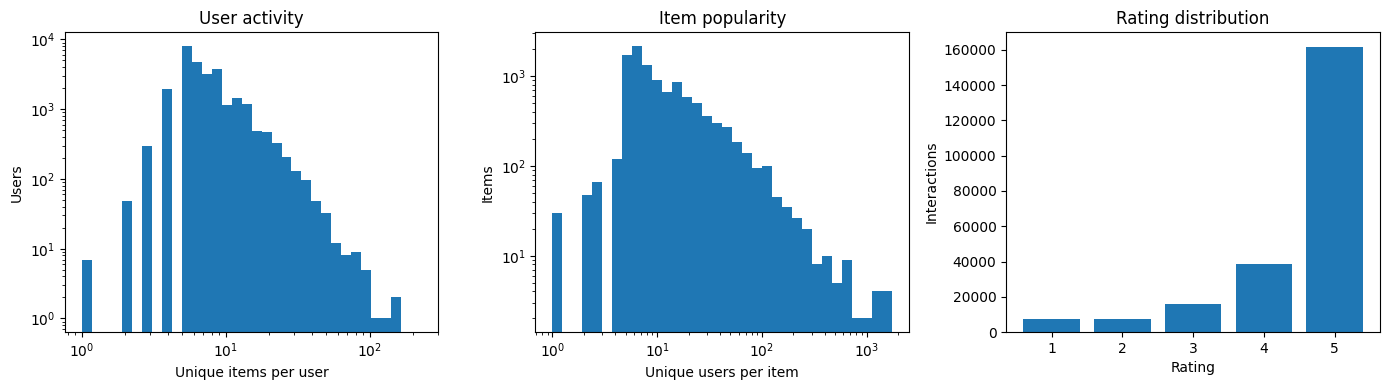

User activity:


count    27530.000000
mean         7.960625
std          5.890834
min          1.000000
25%          5.000000
50%          6.000000
75%          9.000000
max        229.000000
Name: item_id, dtype: float64

Item popularity:


count    10620.000000
mean        20.636158
std         58.183222
min          1.000000
25%          6.000000
50%          9.000000
75%         18.000000
max       1756.000000
Name: user_id, dtype: float64

Interaction matrix density: 0.0750%


In [162]:
user_counts = reviews.groupby("user_id")["item_id"].nunique()
item_counts = reviews.groupby("item_id")["user_id"].nunique()
rating_counts = reviews["rating"].value_counts().sort_index()

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].hist(
    user_counts,
    bins=np.logspace(np.log10(user_counts.min()), np.log10(user_counts.max()), 35)
)
axes[0].set(
    xscale="log",
    yscale="log",
    xlabel="Unique items per user",
    ylabel="Users",
    title="User activity"
)

axes[1].hist(
    item_counts,
    bins=np.logspace(np.log10(item_counts.min()), np.log10(item_counts.max()), 35)
)
axes[1].set(
    xscale="log",
    yscale="log",
    xlabel="Unique users per item",
    ylabel="Items",
    title="Item popularity"
)

axes[2].bar(rating_counts.index, rating_counts.values)
axes[2].set(
    xlabel="Rating",
    ylabel="Interactions",
    title="Rating distribution"
)

plt.tight_layout()
plt.show()

print("User activity:")
display(user_counts.describe())

print("Item popularity:")
display(item_counts.describe())

n_pairs = reviews[["user_id", "item_id"]].drop_duplicates().shape[0]
density = n_pairs / (reviews["user_id"].nunique() * reviews["item_id"].nunique())
print(f"Interaction matrix density: {density:.4%}")

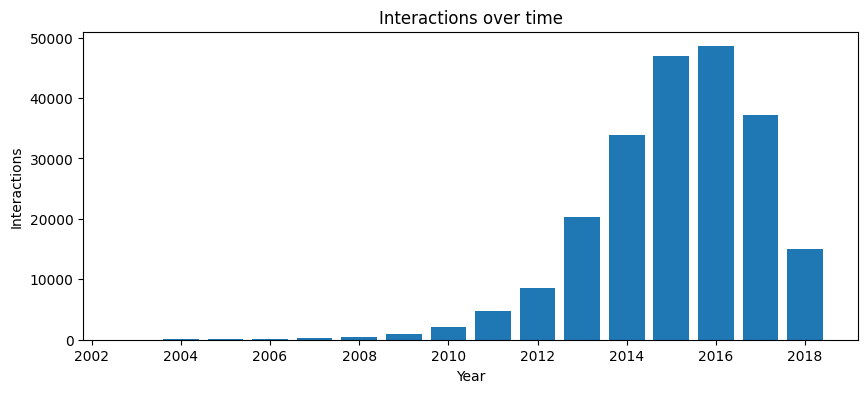

,n_items,n_users,n_interactions,retained_share
0,1000,26124,109340,0.499
1,2000,27144,139363,0.636
2,3000,27421,158258,0.722
3,4000,27477,172186,0.786
4,5000,27503,183092,0.835


In [163]:
unique_pairs = (
    reviews.sort_values(["timestamp", "user_id", "item_id"], kind="stable")
    .drop_duplicates(["user_id", "item_id"])
)

year_counts = unique_pairs["datetime"].dt.year.value_counts().sort_index()

plt.figure(figsize=(10, 4))
plt.bar(year_counts.index, year_counts.values)
plt.xlabel("Year")
plt.ylabel("Interactions")
plt.title("Interactions over time")
plt.show()

popularity = unique_pairs["item_id"].value_counts()

rows = []
for k in [1000, 2000, 3000, 4000, 5000]:
    selected_items = popularity.head(k).index
    subset = unique_pairs[unique_pairs["item_id"].isin(selected_items)]
    rows.append({
        "n_items": k,
        "n_users": subset["user_id"].nunique(),
        "n_interactions": len(subset),
        "retained_share": len(subset) / len(unique_pairs)
    })

display(pd.DataFrame(rows).round(3))

In [164]:
cutoff = pd.Timestamp("2017-01-01", tz="UTC")
history = unique_pairs[unique_pairs["datetime"] < cutoff]

popularity = (
    history.groupby("item_id")["user_id"]
    .nunique()
    .reset_index(name="n_users")
    .sort_values(["n_users", "item_id"], ascending=[False, True])
)

results = []

for k in [2000, 3000, 4000]:
    selected_items = popularity["item_id"].head(k)

    subset = unique_pairs[
        unique_pairs["item_id"].isin(selected_items)
    ]

    user_counts = subset.groupby("user_id")["item_id"].nunique()

    results.append({
        "n_items": subset["item_id"].nunique(),
        "n_users": subset["user_id"].nunique(),
        "n_interactions": len(subset),
        "users_with_5+_items": (user_counts >= 5).sum()
    })

display(pd.DataFrame(results))

,n_items,n_users,n_interactions,users_with_5+_items
0,2000,27122,137098,12208
1,3000,27384,155628,14843
2,4000,27465,169294,16913


### Результаты EDA и обработка дубликатов

Матрица взаимодействий исходного датасета сильно разрежена: плотность уникальных пар пользователь–товар составляет около 0,075%.

Распределения активности пользователей и популярности товаров неравномерны: большинство пользователей оценивают небольшое число товаров, а некоторые товары имеют значительно больше отзывов, чем остальные. Оценки также смещены в сторону высоких значений.

Пропусков в основных полях отзывов нет, однако обнаружены повторные оценки одних и тех же товаров. Всего имеется 11 433 пары пользователь–товар с повторными отзывами, у 630 пар различаются оценки, у 1 609 — даты.

Для получения единственной оценки каждой пары сохраняется самая ранняя дата взаимодействия. Если на эту дату имеется несколько различных оценок, используется их среднее. Более поздние повторные отзывы исключаются.

Такой подход исключает повторение одной пары в разных временных выборках и сохраняет первоначальную дату взаимодействия. После удаления дубликатов остаётся 219 156 взаимодействий.

In [165]:
first_timestamp = reviews.groupby(
    ["user_id", "item_id"]
)["timestamp"].transform("min")

reviews_first = reviews[
    reviews["timestamp"] == first_timestamp
].copy()

reviews_first = reviews_first.drop_duplicates(
    subset=["user_id", "item_id", "rating", "timestamp"]
)

reviews_clean = reviews_first.groupby(
    ["user_id", "item_id"], as_index=False
).agg(
    rating=("rating", "mean"),
    timestamp=("timestamp", "first")
)

reviews_clean["datetime"] = pd.to_datetime(
    reviews_clean["timestamp"], unit="s", utc=True
)

print("Before:", len(reviews))
print("After:", len(reviews_clean))
print("Duplicate pairs:", reviews_clean.duplicated(["user_id", "item_id"]).sum())

Before: 231392
After: 219156
Duplicate pairs: 0


In [166]:
assert not reviews_clean.duplicated(["user_id", "item_id"]).any()
assert reviews_clean["rating"].between(1, 5).all()
assert reviews_clean.notna().all().all()

print("Interactions:", len(reviews_clean))
print("Users:", reviews_clean["user_id"].nunique())
print("Items:", reviews_clean["item_id"].nunique())

print("Mean rating:", round(reviews_clean["rating"].mean(), 3))
print("Positive ratings (>= 4):", round((reviews_clean["rating"] >= 4).mean(), 3))

print("Ratings by value:")
display(reviews_clean["rating"].value_counts().sort_index())

print("Interactions by year:")
display(reviews_clean["datetime"].dt.year.value_counts().sort_index())

Interactions: 219156
Users: 27530
Items: 10620
Mean rating: 4.471
Positive ratings (>= 4): 0.867
Ratings by value:


rating
1.000000      7042
1.500000         8
2.000000      6872
2.500000        12
3.000000     15158
3.333333         1
3.500000        36
4.000000     36740
4.500000        86
5.000000    153201
Name: count, dtype: int64

Interactions by year:


datetime
2003        1
2004       43
2005       43
2006       83
2007      207
2008      439
2009      946
2010     2188
2011     4794
2012     8482
2013    20340
2014    33913
2015    46960
2016    48545
2017    37220
2018    14952
Name: count, dtype: int64

In [167]:
import html

items_clean = items.copy()

items_clean["title"] = items_clean["title"].apply(
    lambda x: html.unescape(x).strip()
)

items_clean["brand"] = items_clean["brand"].fillna("").apply(
    lambda x: html.unescape(x).strip()
)
items_clean.loc[items_clean["brand"] == "", "brand"] = "Unknown"

def clean_categories(categories):
    if not isinstance(categories, list):
        return ["Unknown"]

    categories = [
        html.unescape(c).strip()
        for c in categories
        if isinstance(c, str) and c.strip()
    ]
    return categories if categories else ["Unknown"]

items_clean["category"] = items_clean["category"].apply(clean_categories)

reviews_ready = reviews_clean[
    reviews_clean["item_id"].isin(items_clean["item_id"])
].copy()

print("Interactions removed:", len(reviews_clean) - len(reviews_ready))
print("Remaining interactions:", len(reviews_ready))
print("Remaining users:", reviews_ready["user_id"].nunique())
print("Remaining items:", reviews_ready["item_id"].nunique())

print("Unknown brands:", (items_clean["brand"] == "Unknown").sum())
print("Unknown categories:", items_clean["category"].apply(lambda x: x == ["Unknown"]).sum())


Interactions removed: 65
Remaining interactions: 219091
Remaining users: 27530
Remaining items: 10611
Unknown brands: 92
Unknown categories: 281


### Формирование итогового каталога

В исходных метаданных обнаружены пустые значения брендов и категорий, которые заменяются на `Unknown`. Также нормализуются HTML-сущности в названиях и категориях. Для 9 товаров метаданные отсутствуют полностью; связанные с ними 65 взаимодействий исключаются.

Для ограничения вычислительной сложности выбираются 3 000 наиболее популярных товаров по количеству уникальных пользователей до 1 января 2017 года. Таким образом, выбор каталога не использует взаимодействия из будущих периодов.

После ограничения каталога остаётся 155 628 взаимодействий и 27 384 пользователя. Плотность соответствующей матрицы составляет около 0,189%.

Для итогового эксперимента оставляем пользователей, имеющих не менее трёх взаимодействий в обучающем периоде. Такое ограничение обеспечивает минимальную историю для персонализации рекомендаций.

In [168]:
N_ITEMS = 3000
TRAIN_END = pd.Timestamp("2017-01-01", tz="UTC")

history = reviews_ready[reviews_ready["datetime"] < TRAIN_END]

item_popularity = (
    history.groupby("item_id")["user_id"]
    .nunique()
    .reset_index(name="n_users")
    .sort_values(["n_users", "item_id"], ascending=[False, True])
)

selected_items = item_popularity.head(N_ITEMS)["item_id"]

reviews_subset = reviews_ready[
    reviews_ready["item_id"].isin(selected_items)
].copy()

items_subset = items_clean[
    items_clean["item_id"].isin(selected_items)
].copy()

print("Interactions:", len(reviews_subset))
print("Users:", reviews_subset["user_id"].nunique())
print("Items:", reviews_subset["item_id"].nunique())
print("Density:", round(
    len(reviews_subset) /
    (reviews_subset["user_id"].nunique() * reviews_subset["item_id"].nunique()) * 100, 3
), "%")

Interactions: 155628
Users: 27384
Items: 3000
Density: 0.189 %


In [169]:
VALID_END = pd.Timestamp("2018-01-01", tz="UTC")

train_period = reviews_subset[reviews_subset["datetime"] < TRAIN_END]
valid_period = reviews_subset[
    (reviews_subset["datetime"] >= TRAIN_END) &
    (reviews_subset["datetime"] < VALID_END)
]
test_period = reviews_subset[reviews_subset["datetime"] >= VALID_END]

period_stats = pd.DataFrame([
    {
        "period": name,
        "interactions": len(df),
        "users": df["user_id"].nunique(),
        "items": df["item_id"].nunique()
    }
    for name, df in [
        ("Train: before 2017", train_period),
        ("Validation: 2017", valid_period),
        ("Test: 2018", test_period)
    ]
])

display(period_stats)

train_user_counts = train_period.groupby("user_id").size()

activity_stats = pd.DataFrame([
    {
        "min_interactions": k,
        "users": (train_user_counts >= k).sum(),
        "train_interactions": train_user_counts[train_user_counts >= k].sum()
    }
    for k in [2, 3, 5, 8, 10]
])

display(activity_stats)

train_users = set(train_period["user_id"])

print("Validation users present in train:",
      valid_period["user_id"].isin(train_users).sum())

print("Test users present in train:",
      test_period["user_id"].isin(train_users).sum())

,period,interactions,users,items
0,Train: before 2017,123025,24158,3000
1,Validation: 2017,23640,8674,2555
2,Test: 2018,8963,3959,1947


,min_interactions,users,train_interactions
0,2,22203,121070
1,3,19318,115300
2,5,11154,86462
3,8,3637,43764
4,10,2080,30645


Validation users present in train: 13629
Test users present in train: 4777


## 2. Протокол эксперимента

Используется глобальное хронологическое разбиение:

- **Train:** взаимодействия до 1 января 2017 года;
- **Validation:** взаимодействия за 2017 год;
- **Test:** взаимодействия за 2018 год.

На этапе подбора гиперпараметров модели обучаются только на train и оцениваются на validation. После выбора настроек каждая модель обучается заново на train + validation, а test используется однократно для итогового сравнения.

Рассматривается **warm-start сценарий**: в validation и test оставляются только пользователи и товары, присутствовавшие в первоначальном train. Новые пользователи и новые товары исключаются из оценки; задача холодного старта отдельно не исследуется.

В качестве кандидатов используется единый каталог из 3 000 товаров, сформированный по историческим данным train. Для каждого пользователя из кандидатов исключаются все товары, уже присутствующие в его обучающей истории, независимо от поставленной оценки.

После всех ограничений получены 115 300 взаимодействий train, 8 046 — validation и 2 711 — test, всего 126 057 взаимодействий.

Все модели используют одинаковые разбиения, набор кандидатов, критерий релевантности и правила исключения известных товаров. Различаются только алгоритмы обучения и функции вычисления рекомендательных скоров.

In [170]:
MIN_TRAIN_INTERACTIONS = 3

train_counts = train_period.groupby("user_id").size()
selected_users = train_counts[
    train_counts >= MIN_TRAIN_INTERACTIONS
].index

train = train_period[
    train_period["user_id"].isin(selected_users)
].copy()

train_items = set(train["item_id"])

valid = valid_period[
    valid_period["user_id"].isin(selected_users) &
    valid_period["item_id"].isin(train_items)
].copy()

test = test_period[
    test_period["user_id"].isin(selected_users) &
    test_period["item_id"].isin(train_items)
].copy()

split_stats = pd.DataFrame([
    {
        "split": name,
        "interactions": len(df),
        "users": df["user_id"].nunique(),
        "items": df["item_id"].nunique(),
        "positive_interactions": (df["rating"] >= 4).sum(),
        "users_with_positive": df.loc[
            df["rating"] >= 4, "user_id"
        ].nunique()
    }
    for name, df in [
        ("Train", train),
        ("Validation", valid),
        ("Test", test)
    ]
])

display(split_stats)

print("Total interactions:", len(train) + len(valid) + len(test))
print("Train unique user-item pairs:",
      not train.duplicated(["user_id", "item_id"]).any())
print("Train items:", len(train_items))

,split,interactions,users,items,positive_interactions,users_with_positive
0,Train,115300,19318,3000,101138,19197
1,Validation,8046,3842,2005,6894,3434
2,Test,2711,1624,1192,2267,1391


Total interactions: 126057
Train unique user-item pairs: True
Train items: 3000


In [171]:
user_ids = np.sort(train["user_id"].unique())
item_ids = np.sort(train["item_id"].unique())

user_to_idx = {user_id: i for i, user_id in enumerate(user_ids)}
item_to_idx = {item_id: i for i, item_id in enumerate(item_ids)}

n_users = len(user_ids)
n_items = len(item_ids)

def add_indices(df):
    result = df.copy()
    result["user_idx"] = result["user_id"].map(user_to_idx).astype(int)
    result["item_idx"] = result["item_id"].map(item_to_idx).astype(int)
    return result

train_idx = add_indices(train)
valid_idx = add_indices(valid)
test_idx = add_indices(test)

print("Users:", n_users)
print("Items:", n_items)


Users: 19318
Items: 3000


In [172]:
R_train = sparse.csr_matrix(
    (
        train_idx["rating"].to_numpy(),
        (train_idx["user_idx"].to_numpy(),
         train_idx["item_idx"].to_numpy())
    ),
    shape=(n_users, n_items)
)

print("Matrix shape:", R_train.shape)
print("Observed ratings:", R_train.nnz)
print("Density:", R_train.nnz / (n_users * n_items))

assert R_train.nnz == len(train_idx)

Matrix shape: (19318, 3000)
Observed ratings: 115300
Density: 0.001989508920868275


## 3. Метрики качества Top-10

Для всех моделей используется единый критерий релевантности: товар считается релевантным, если его оценка в отложенной выборке не ниже 4.

**Основная метрика — NDCG@10.** Она учитывает не только наличие релевантных товаров в рекомендациях, но и их позиции: попадания в начало списка получают больший вес.

Дополнительно используются:

- **Recall@10** — доля известных релевантных товаров пользователя, найденных в Top-10;
- **HitRate@10** — доля пользователей, у которых в Top-10 найден хотя бы один релевантный товар;
- **Graded NDCG@10** — версия NDCG с учётом величины положительных оценок.

Для бинарной NDCG применяется релевантность 0 или 1. Для Graded NDCG положительным оценкам соответствует уровень релевантности $r-3$, а дисконтированный выигрыш вычисляется как $(2^{r-3}-1)/\log_2(k+1)$.

Метрики усредняются по пользователям, имеющим хотя бы одно положительное взаимодействие в соответствующей отложенной выборке. В validation таких пользователей 3 434, в test — 1 391.

**До подбора гиперпараметров фиксируем NDCG@10 как основной критерий выбора конфигурации.** Остальные метрики рассчитываются для каждой конфигурации, но не используются для её выбора.

Отсутствующие взаимодействия не считаются достоверно отрицательными: оценивается способность найти известные положительные товары среди полного каталога кандидатов.

In [173]:
def evaluate_topk(recommend_fn, heldout, k=10):
    positive = heldout[heldout["rating"] >= 4]
    discounts = 1 / np.log2(np.arange(2, k + 2))

    results = []

    for user_idx, group in positive.groupby("user_idx"):
        true_items = dict(zip(
            group["item_idx"],
            group["rating"]
        ))
        top = recommend_fn(int(user_idx), k=k)

        binary = np.array([
            int(item in true_items) for item in top
        ])

        graded = np.array([
            max(0, true_items.get(item, 0) - 3)
            for item in top
        ])

        recall = binary.sum() / len(true_items)
        hitrate = float(binary.sum() > 0)

        dcg_binary = (binary * discounts).sum()
        idcg_binary = discounts[:min(len(true_items), k)].sum()
        ndcg_binary = dcg_binary / idcg_binary

        gains = 2 ** graded - 1
        dcg_graded = (gains * discounts).sum()

        ideal = np.sort(
            np.array(list(true_items.values())) - 3
        )[::-1][:k]

        idcg_graded = (
            (2 ** ideal - 1) * discounts[:len(ideal)]
        ).sum()

        ndcg_graded = dcg_graded / idcg_graded

        results.append({
            "Recall@10": recall,
            "HitRate@10": hitrate,
            "NDCG@10": ndcg_binary,
            "Graded NDCG@10": ndcg_graded
        })

    return pd.DataFrame(results).mean()

## 4. Item-based Collaborative Filtering

Коллаборативная фильтрация на основе сходства товаров.

Используется **Adjusted Cosine Similarity**: перед вычислением сходства из наблюдаемых оценок вычитается средняя оценка соответствующего пользователя.

Для уменьшения влияния случайных совпадений применяется shrinkage:

$$
s_{ij}=\operatorname{cos}(i,j)\frac{n_{ij}}{n_{ij}+\lambda},
$$

где $n_{ij}$ — число пользователей, оценивших оба товара. Если общих пользователей меньше `min_common`, сходство обнуляется.

Предсказанная оценка вычисляется как средняя оценка пользователя плюс взвешенное отклонение оценок положительно похожих товаров из его истории.

При недостаточном числе подходящих соседей Top-10 дополняется популярными товарами из обучающей выборки, не встречавшимися в истории пользователя.

**Подбор гиперпараметров на validation:**

- `min_common`: 1, 2, 3;
- `shrinkage`: 0, 10, 30.

Лучшая конфигурация: `min_common=3`, `shrinkage=10`. NDCG@10 на validation составила 0,0170.

In [174]:
n_ratings = np.diff(R_train.indptr)

user_mean = (
    np.asarray(R_train.sum(axis=1)).ravel() / n_ratings
)

R_centered = R_train.astype(np.float32).copy()
R_centered.data -= np.repeat(user_mean, n_ratings)
item_dot = (R_centered.T @ R_centered).toarray()

item_norms = np.sqrt(np.maximum(np.diag(item_dot), 0))
denominator = np.outer(item_norms, item_norms)

item_cosine = np.divide(
    item_dot,
    denominator,
    out=np.zeros_like(item_dot),
    where=denominator > 0
)

R_binary = R_train.copy()
R_binary.data[:] = 1.0

item_common = (R_binary.T @ R_binary).toarray()

print("Similarity matrix:", item_cosine.shape)
print("Common-users matrix:", item_common.shape)
print("Cosine range:", item_cosine.min(), item_cosine.max())
print("Pairs with >= 3 common users:",
      np.count_nonzero(np.triu(item_common >= 3, k=1)))

Similarity matrix: (3000, 3000)
Common-users matrix: (3000, 3000)
Cosine range: -0.65897363 1.0000001
Pairs with >= 3 common users: 23000


In [175]:
def make_item_similarity(cosine, common, min_common=3, shrinkage=10):
    weights = np.divide(
        common,
        common + shrinkage,
        out=np.zeros_like(common, dtype=np.float32),
        where=(common + shrinkage) > 0
    )

    similarity = cosine * weights
    similarity[common < min_common] = 0.0
    np.fill_diagonal(similarity, 0.0)

    return similarity

In [176]:
def item_cf_scores(user_idx, similarity, R, user_means):
    row = R.getrow(user_idx)
    seen_items = row.indices
    seen_ratings = row.data

    similarities = np.maximum(
        similarity[:, seen_items], 0
    )

    deviations = seen_ratings - user_means[user_idx]

    numerator = similarities @ deviations
    denominator = similarities.sum(axis=1)

    scores = np.full(R.shape[1], np.nan)
    valid = denominator > 0

    scores[valid] = (
        user_means[user_idx]
        + numerator[valid] / denominator[valid]
    )

    scores[seen_items] = np.nan

    return scores

In [177]:

popularity = np.bincount(
    train_idx.loc[train_idx["rating"] >= 4, "item_idx"].to_numpy(),
    minlength=n_items
)

popular_items = np.argsort(-popularity, kind="stable")


def recommend_item_cf(
    user_idx, similarity, k=10,
    R=R_train, user_means=user_mean,
    popularity_order=popular_items
):
    scores = item_cf_scores(user_idx, similarity, R, user_means)

    candidates = np.flatnonzero(np.isfinite(scores))
    ranked = candidates[
        np.lexsort((candidates, -scores[candidates]))
    ]

    top = ranked[:k].tolist()

    if len(top) < k:
        seen = set(R.getrow(user_idx).indices)
        selected = set(top)

        for item in popularity_order:
            if item not in seen and item not in selected:
                top.append(int(item))
                if len(top) == k:
                    break

    return np.array(top, dtype=int)

In [178]:
MIN_COMMON_VALUES = [1, 2, 3]
SHRINKAGE_VALUES = [0, 10, 30]

search_results = []

for min_common in MIN_COMMON_VALUES:
    for shrinkage in SHRINKAGE_VALUES:

        similarity = make_item_similarity(
            item_cosine,
            item_common,
            min_common=min_common,
            shrinkage=shrinkage
        )

        metrics = evaluate_topk(
            recommend_fn=lambda u, k=10: recommend_item_cf(
                u, similarity, k=k
            ),
            heldout=valid_idx,
            k=10
        )

        search_results.append({
            "min_common": min_common,
            "shrinkage": shrinkage,
            **metrics.to_dict()
        })

cf_search = pd.DataFrame(search_results)
cf_search = cf_search.sort_values(
    "NDCG@10", ascending=False
).reset_index(drop=True)

display(cf_search.round(4))

best_cf_params = {
    "min_common": int(cf_search.loc[0, "min_common"]),
    "shrinkage": int(cf_search.loc[0, "shrinkage"])
}

print("Best parameters:", best_cf_params)

,min_common,shrinkage,Recall@10,HitRate@10,NDCG@10,Graded NDCG@10
0,3,10,0.0262,0.0431,0.0170,0.0170
1,3,0,0.0258,0.0422,0.0162,0.0162
2,3,30,0.0249,0.0414,0.0147,0.0147
3,2,10,0.0166,0.0315,0.0108,0.0107
4,2,0,0.0168,0.0312,0.0103,0.0102
5,2,30,0.0157,0.0288,0.0096,0.0095
6,1,10,0.0100,0.0166,0.0053,0.0050
7,1,0,0.0094,0.0166,0.0053,0.0052
8,1,30,0.0077,0.0143,0.0043,0.0041


Best parameters: {'min_common': 3, 'shrinkage': 10}


In [179]:
def recommend_popularity(user_idx, k=10):
    seen = set(R_train.getrow(user_idx).indices)

    top = [
        int(item)
        for item in popular_items
        if item not in seen
    ][:k]

    return np.array(top, dtype=int)


pop_metrics = evaluate_topk(
    recommend_fn=recommend_popularity,
    heldout=valid_idx,
    k=10
)

comparison = pd.DataFrame({
    "Item-based CF": cf_search.iloc[0][[
        "Recall@10", "HitRate@10", "NDCG@10", "Graded NDCG@10"
    ]],
    "Popularity": pop_metrics
})

display(comparison.round(4))

,Item-based CF,Popularity
Recall@10,0.0262,0.0333
HitRate@10,0.0431,0.0565
NDCG@10,0.0170,0.0224
Graded NDCG@10,0.0170,0.0217


## 5. Explicit ALS

Explicit ALS представляет пользователей и товары латентными векторами и восстанавливает наблюдаемые числовые оценки через их скалярное произведение:

$$
\hat r_{ui}=p_u^\top q_i.
$$

Модель минимизирует сумму квадратов ошибок на наблюдаемых взаимодействиях с L2-регуляризацией:

$$
\mathcal L=
\sum_{(u,i)\in\Omega}(r_{ui}-p_u^\top q_i)^2+
\lambda(\|P\|_F^2+\|Q\|_F^2).
$$

Обучение выполняется методом Alternating Least Squares: попеременно фиксируются факторы товаров и пользователей, а соответствующие параметры обновляются решением регуляризованных систем линейных уравнений.

Отсутствующие оценки не используются как нулевые целевые значения. Реализована базовая версия Explicit ALS без дополнительных пользовательских и товарных смещений.

**Подбор гиперпараметров:**

- `n_factors`: 8, 16;
- `reg`: 0.1, 1, 5, 10, 20;
- `n_iters`: 3, 5.

Лучшая конфигурация: 16 факторов, регуляризация 20, три итерации. NDCG@10 на validation составила 0,0233.

In [180]:
class ExplicitALS:
    def __init__(self, n_factors=16, n_iters=5, reg=1.0, seed=42):
        self.n_factors = n_factors
        self.n_iters = n_iters
        self.reg = reg
        self.seed = seed

    def fit(self, R):
        R = R.tocsr().astype(np.float64)
        R_csc = R.tocsc()

        n_users, n_items = R.shape
        rng = np.random.default_rng(self.seed)

        self.user_factors = rng.normal(
            0, 0.1, size=(n_users, self.n_factors)
        )
        self.item_factors = rng.normal(
            0, 0.1, size=(n_items, self.n_factors)
        )

        eye = np.eye(self.n_factors)
        observed = R.tocoo()
        self.train_rmse = []

        for iteration in range(self.n_iters):

            for u in range(n_users):
                start, end = R.indptr[u:u + 2]
                items = R.indices[start:end]
                ratings = R.data[start:end]

                Q = self.item_factors[items]

                self.user_factors[u] = np.linalg.solve(
                    Q.T @ Q + self.reg * eye,
                    Q.T @ ratings
                )

            for i in range(n_items):
                start, end = R_csc.indptr[i:i + 2]
                users = R_csc.indices[start:end]
                ratings = R_csc.data[start:end]

                P = self.user_factors[users]

                self.item_factors[i] = np.linalg.solve(
                    P.T @ P + self.reg * eye,
                    P.T @ ratings
                )

            predictions = self.predict_pairs(
                observed.row, observed.col
            )
            rmse = np.sqrt(np.mean(
                (observed.data - predictions) ** 2
            ))
            self.train_rmse.append(rmse)

        return self

    def predict_pairs(self, user_idx, item_idx):
        return np.sum(
            self.user_factors[user_idx] *
            self.item_factors[item_idx],
            axis=1
        )

    def scores_for_user(self, user_idx):
        return self.item_factors @ self.user_factors[user_idx]

In [181]:
def recommend_als(user_idx, model, R, k=10):
    scores = model.scores_for_user(user_idx).copy()

    seen_items = R.getrow(user_idx).indices
    scores[seen_items] = -np.inf

    candidates = np.flatnonzero(np.isfinite(scores))
    ranked = candidates[
        np.lexsort((candidates, -scores[candidates]))
    ]

    return ranked[:k]

In [182]:
from itertools import product
from contextlib import nullcontext

try:
    from threadpoolctl import threadpool_limits
except ImportError:
    threadpool_limits = None

als_results = []

for n_factors, reg, n_iters in product(
    [8, 16],
    [0.1, 1.0, 5.0, 10.0, 20.0],
    [3, 5]
):
    model = ExplicitALS(
        n_factors=n_factors,
        n_iters=n_iters,
        reg=reg,
        seed=SEED
    )

    context = (
        threadpool_limits(limits=1, user_api="blas")
        if threadpool_limits is not None
        else nullcontext()
    )

    with context:
        model.fit(R_train)

    metrics = evaluate_topk(
        recommend_fn=lambda u, k=10: recommend_als(
            u, model, R_train, k=k
        ),
        heldout=valid_idx,
        k=10
    )

    als_results.append({
        "n_factors": n_factors,
        "reg": reg,
        "n_iters": n_iters,
        "Train RMSE": model.train_rmse[-1],
        **metrics.to_dict()
    })

als_search = pd.DataFrame(als_results)
als_search = als_search.sort_values(
    "NDCG@10", ascending=False
).reset_index(drop=True)

display(als_search.round(4))

best_als_params = {
    "n_factors": int(als_search.loc[0, "n_factors"]),
    "reg": float(als_search.loc[0, "reg"]),
    "n_iters": int(als_search.loc[0, "n_iters"])
}

print("Best parameters:", best_als_params)

,n_factors,reg,n_iters,Train RMSE,Recall@10,HitRate@10,NDCG@10,Graded NDCG@10
0,16,20.0,3,1.8964,0.0349,0.0556,0.0233,0.0225
1,8,20.0,3,1.9080,0.0345,0.0553,0.0224,0.0217
2,8,10.0,5,1.0975,0.0345,0.0553,0.0223,0.0218
3,8,20.0,5,1.7129,0.0316,0.0501,0.0216,0.0211
4,16,20.0,5,1.7010,0.0317,0.0495,0.0213,0.0206
5,8,10.0,3,1.2294,0.0312,0.0533,0.0207,0.0200
6,16,10.0,3,1.1646,0.0308,0.0536,0.0201,0.0193
7,16,10.0,5,1.0660,0.0294,0.0518,0.0201,0.0192
8,8,5.0,5,0.7021,0.0284,0.0486,0.0182,0.0175
9,8,5.0,3,0.8763,0.0273,0.0457,0.0169,0.0165


Best parameters: {'n_factors': 16, 'reg': 20.0, 'n_iters': 3}


In [183]:
mean_rating = train_idx["rating"].mean()

train_mean_rmse = np.sqrt(
    np.mean((train_idx["rating"] - mean_rating) ** 2)
)

valid_mean_rmse = np.sqrt(
    np.mean((valid_idx["rating"] - mean_rating) ** 2)
)

print("Mean baseline Train RMSE:", round(train_mean_rmse, 4))
print("Mean baseline Valid RMSE:", round(valid_mean_rmse, 4))

Mean baseline Train RMSE: 0.9369
Mean baseline Valid RMSE: 1.0249


In [184]:
mu = R_train.data.mean()

R_residual = R_train.astype(np.float64).copy()
R_residual.data -= mu

def valid_rmse(model, offset=0.0):
    predictions = model.predict_pairs(
        valid_idx["user_idx"].to_numpy(),
        valid_idx["item_idx"].to_numpy()
    ) + offset

    return np.sqrt(np.mean(
        (valid_idx["rating"].to_numpy() - predictions) ** 2
    ))

In [185]:
centered_results = []

for n_factors, reg, n_iters in product(
    [8, 16],
    [0.1, 1.0, 5.0, 10.0, 20.0],
    [3, 5]
):
    model = ExplicitALS(
        n_factors=n_factors,
        n_iters=n_iters,
        reg=reg,
        seed=SEED
    )

    context = (
        threadpool_limits(limits=1, user_api="blas")
        if threadpool_limits is not None
        else nullcontext()
    )

    with context:
        model.fit(R_residual)

    metrics = evaluate_topk(
        recommend_fn=lambda u, k=10: recommend_als(
            u, model, R_train, k=k
        ),
        heldout=valid_idx,
        k=10
    )

    centered_results.append({
        "n_factors": n_factors,
        "reg": reg,
        "n_iters": n_iters,
        "Train RMSE": model.train_rmse[-1],
        "Valid RMSE": valid_rmse(model, offset=mu),
        **metrics.to_dict()
    })

centered_search = pd.DataFrame(centered_results)
centered_search = centered_search.sort_values(
    "NDCG@10", ascending=False
).reset_index(drop=True)

display(centered_search.round(4))

best_centered_params = {
    "n_factors": int(centered_search.loc[0, "n_factors"]),
    "reg": float(centered_search.loc[0, "reg"]),
    "n_iters": int(centered_search.loc[0, "n_iters"])
}

print("Best centered ALS parameters:", best_centered_params)

,n_factors,reg,n_iters,Train RMSE,Valid RMSE,Recall@10,HitRate@10,NDCG@10,Graded NDCG@10
0,8,20.0,3,0.9143,1.0244,0.0236,0.0402,0.0172,0.0171
1,8,20.0,5,0.9104,1.0242,0.0225,0.0396,0.0166,0.0163
2,16,20.0,5,0.9092,1.0245,0.0233,0.0411,0.0165,0.0161
3,16,20.0,3,0.9135,1.0249,0.0223,0.0379,0.0161,0.0157
4,8,10.0,3,0.8554,1.0253,0.0213,0.0373,0.0128,0.0125
5,8,10.0,5,0.8318,1.0249,0.0213,0.0393,0.0127,0.0122
6,16,10.0,5,0.8240,1.0253,0.0205,0.0376,0.0127,0.0120
7,16,10.0,3,0.8438,1.0265,0.0182,0.0352,0.0111,0.0106
8,8,5.0,3,0.6607,1.0586,0.0158,0.0282,0.0087,0.0085
9,16,5.0,5,0.5884,1.0416,0.0151,0.0294,0.0086,0.0081


Best centered ALS parameters: {'n_factors': 8, 'reg': 20.0, 'n_iters': 3}


In [186]:
metrics_cols = [
    "Recall@10", "HitRate@10",
    "NDCG@10", "Graded NDCG@10"
]

comparison = pd.DataFrame({
    "Explicit ALS": als_search.loc[0, metrics_cols],
    "Centered ALS": centered_search.loc[0, metrics_cols]
})

display(comparison.round(4))

,Explicit ALS,Centered ALS
Recall@10,0.0349,0.0236
HitRate@10,0.0556,0.0402
NDCG@10,0.0233,0.0172
Graded NDCG@10,0.0225,0.0171


## 6. EASE

EASE (Embarrassingly Shallow Autoencoder) моделирует линейные зависимости между товарами.

Входная матрица $X$ содержит бинарные положительные взаимодействия: оценкам не ниже 4 соответствует значение 1, остальные значения равны 0.

Оптимизируется функция:

$$
\min_B \|X-XB\|_F^2+\lambda\|B\|_F^2,
\qquad \operatorname{diag}(B)=0.
$$

Решение вычисляется аналитически. Если

$$
P=(X^\top X+\lambda I)^{-1},
$$

то для недиагональных элементов:

$$
B_{ij}=-\frac{P_{ij}}{P_{jj}}.
$$

Рекомендательные скоры пользователя вычисляются как $s_u=X_uB$. При формировании Top-10 исключаются все ранее оценённые товары, в том числе с низкими оценками.

**Подбираемый гиперпараметр:** коэффициент регуляризации `reg`.

Проверенные значения: 10, 30, 100, 300, 1000, 3000, 10000, 30000, 100000.

Лучшее значение: `reg=100000`. NDCG@10 на validation составила 0,0347.

In [187]:
X_train = R_train.astype(np.float64).copy()

X_train.data = (X_train.data >= 4).astype(np.float64)
X_train.eliminate_zeros()

In [188]:
class EASE:
    def __init__(self, reg=100.0):
        self.reg = reg

    def fit(self, X):
        G = (X.T @ X).toarray()
        G[np.diag_indices_from(G)] += self.reg
        P = np.linalg.solve(G, np.eye(G.shape[0]))


        self.B = -P / np.diag(P)[None, :]
        np.fill_diagonal(self.B, 0.0)

        return self

    def scores_for_user(self, user_idx, X):
        return np.asarray(
            X.getrow(user_idx) @ self.B
        ).ravel()

In [189]:
def recommend_ease(user_idx, model, X, R, k=10):
    scores = model.scores_for_user(user_idx, X).copy()

    seen_items = R.getrow(user_idx).indices
    scores[seen_items] = -np.inf

    return np.argsort(-scores, kind="stable")[:k]

In [190]:
ease_results = []

for reg in [10, 30, 100, 300, 1000, 3000, 10000, 30000, 100000]:
    model = EASE(reg=reg).fit(X_train)

    metrics = evaluate_topk(
        recommend_fn=lambda u, k=10: recommend_ease(
            u, model, X_train, R_train, k=k
        ),
        heldout=valid_idx,
        k=10
    )

    ease_results.append({
        "reg": reg,
        **metrics.to_dict()
    })

ease_search = pd.DataFrame(ease_results)
ease_search = ease_search.sort_values(
    "NDCG@10", ascending=False
).reset_index(drop=True)

display(ease_search.round(4))

best_ease_params = {
    "reg": float(ease_search.loc[0, "reg"])
}

print("Best EASE parameters:", best_ease_params)

,reg,Recall@10,HitRate@10,NDCG@10,Graded NDCG@10
0,100000,0.0520,0.0842,0.0347,0.0339
1,10000,0.0529,0.0850,0.0343,0.0337
2,30000,0.0520,0.0842,0.0341,0.0334
3,3000,0.0568,0.0926,0.0333,0.0329
4,1000,0.0544,0.0906,0.0308,0.0303
5,100,0.0516,0.0842,0.0288,0.0286
6,300,0.0520,0.0850,0.0286,0.0284
7,30,0.0478,0.0778,0.0276,0.0273
8,10,0.0427,0.0711,0.0255,0.0252


Best EASE parameters: {'reg': 100000.0}


## 7. Factorization Machines

Factorization Machines позволяют использовать дополнительные признаки пользователей и товаров.

Для каждого взаимодействия формируются четыре категориальных признака:

1. Идентификатор пользователя.
2. Идентификатор товара.
3. Бренд товара.
4. Последняя, наиболее конкретная категория товара.

В выбранном каталоге закодированы 671 бренд и 306 категорий. Все категориальные признаки переводятся в целочисленные индексы с непересекающимися диапазонами.

Используется Factorization Machine второго порядка:

$$
\hat r(x)=w_0+\sum_i w_ix_i+
\sum_{i<j}\langle v_i,v_j\rangle x_ix_j.
$$

Модель обучается на явных рейтингах минимизацией MSE с помощью Adam. Попарные взаимодействия признаков вычисляются через латентные векторы, включая взаимодействия пользователя с брендом и категорией.

Метаданные товаров рассматриваются как статические признаки. Поведенческие характеристики, вычисленные по будущим отзывам, в FM не используются.

**Подбор гиперпараметров:**

- `n_factors`: 8, 16;
- `weight_decay`: 0.00001, 0.001, 0.01;
- `n_epochs`: 3, 6.

Скорость обучения фиксируется равной 0.005.

Лучшая конфигурация: 16 факторов, `weight_decay=0.001`, три эпохи. NDCG@10 на validation составила 0,0067.

In [191]:
item_meta = (
    items.drop_duplicates("item_id")
    .set_index("item_id")
    .reindex(item_ids)
)

def get_category(categories):
    if isinstance(categories, (list, tuple)) and len(categories) > 0:
        return str(categories[-1])
    return "Unknown"

brands = item_meta["brand"].fillna("Unknown").astype(str)
categories = item_meta["category"].apply(get_category)

brand_codes, unique_brands = pd.factorize(brands, sort=True)
category_codes, unique_categories = pd.factorize(categories, sort=True)

n_brands = len(unique_brands)
n_categories = len(unique_categories)

print("Brands:", n_brands)
print("Categories:", n_categories)

Brands: 671
Categories: 306


In [192]:
n_features = n_users + n_items + n_brands + n_categories

def make_fm_features(users, item_indices):
    users = np.asarray(users, dtype=np.int64)
    item_indices = np.asarray(item_indices, dtype=np.int64)

    return np.column_stack([
        users,
        n_users + item_indices,
        n_users + n_items + brand_codes[item_indices],
        n_users + n_items + n_brands + category_codes[item_indices]
    ])

X_fm_train = make_fm_features(
    train_idx["user_idx"].to_numpy(),
    train_idx["item_idx"].to_numpy()
)

y_fm_train = train_idx["rating"].to_numpy(dtype=np.float32)

print("Train features:", X_fm_train.shape)
print("Total features:", n_features)

Train features: (115300, 4)
Total features: 23295


In [193]:
import torch
from torch import nn

class FactorizationMachine(nn.Module):
    def __init__(self, n_features, n_factors=16, global_mean=0.0):
        super().__init__()

        self.bias = nn.Parameter(torch.tensor(float(global_mean)))
        self.linear = nn.Embedding(n_features, 1)
        self.factors = nn.Embedding(n_features, n_factors)

        nn.init.zeros_(self.linear.weight)
        nn.init.normal_(self.factors.weight, std=0.01)

    def forward(self, x):
        linear = self.linear(x).sum(dim=1).squeeze(-1)

        v = self.factors(x)

        interactions = 0.5 * (
            v.sum(dim=1).pow(2)
            - v.pow(2).sum(dim=1)
        ).sum(dim=1)

        return self.bias + linear + interactions

In [194]:
def recommend_fm(user_idx, model, R, k=10):
    features = make_fm_features(
        np.full(n_items, user_idx),
        np.arange(n_items)
    )

    model.eval()
    with torch.no_grad():
        scores = model(
            torch.tensor(features, dtype=torch.long)
        ).numpy().copy()

    scores[R.getrow(user_idx).indices] = -np.inf

    return np.argsort(-scores, kind="stable")[:k]

In [195]:
from itertools import product
from torch.utils.data import TensorDataset, DataLoader

dataset = TensorDataset(
    torch.tensor(X_fm_train, dtype=torch.long),
    torch.tensor(y_fm_train, dtype=torch.float32)
)

loader = DataLoader(dataset, batch_size=2048, shuffle=True)

X_fm_valid = torch.tensor(
    make_fm_features(
        valid_idx["user_idx"].to_numpy(),
        valid_idx["item_idx"].to_numpy()
    ),
    dtype=torch.long
)

y_fm_valid = valid_idx["rating"].to_numpy()

fm_results = []

for n_factors, weight_decay, n_epochs in product(
    [8, 16],
    [1e-5, 1e-3, 1e-2],
    [3, 6]
):
    torch.manual_seed(SEED)

    model = FactorizationMachine(
        n_features=n_features,
        n_factors=n_factors,
        global_mean=y_fm_train.mean()
    )

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.005,
        weight_decay=weight_decay
    )

    for epoch in range(n_epochs):
        model.train()

        for x, y in loader:
            optimizer.zero_grad()

            predictions = model(x)
            loss = ((predictions - y) ** 2).mean()

            loss.backward()
            optimizer.step()

    model.eval()

    with torch.no_grad():
        valid_predictions = model(X_fm_valid).numpy()

    valid_rmse = np.sqrt(
        np.mean((y_fm_valid - valid_predictions) ** 2)
    )

    metrics = evaluate_topk(
        recommend_fn=lambda u, k=10: recommend_fm(
            u, model, R_train, k=k
        ),
        heldout=valid_idx,
        k=10
    )

    fm_results.append({
        "n_factors": n_factors,
        "weight_decay": weight_decay,
        "n_epochs": n_epochs,
        "Valid RMSE": valid_rmse,
        **metrics.to_dict()
    })

fm_search = pd.DataFrame(fm_results)
fm_search = fm_search.sort_values(
    "NDCG@10", ascending=False
).reset_index(drop=True)

display(fm_search.round(5))

best_fm_params = {
    "n_factors": int(fm_search.loc[0, "n_factors"]),
    "weight_decay": float(fm_search.loc[0, "weight_decay"]),
    "n_epochs": int(fm_search.loc[0, "n_epochs"])
}

print("Best FM parameters:", best_fm_params)

,n_factors,weight_decay,n_epochs,Valid RMSE,Recall@10,HitRate@10,NDCG@10,Graded NDCG@10
0,16,0.00100,3,0.99538,0.01119,0.02854,0.00666,0.00671
1,16,0.01000,3,1.00948,0.00977,0.02155,0.00632,0.00626
2,8,0.00100,3,0.99580,0.00902,0.01776,0.00470,0.00467
3,16,0.00100,6,0.99247,0.00679,0.01398,0.00392,0.00388
4,8,0.00001,6,1.03908,0.00624,0.01019,0.00349,0.00351
5,16,0.00001,6,1.04776,0.00591,0.01048,0.00332,0.00332
6,16,0.01000,6,1.00899,0.00501,0.00815,0.00287,0.00294
7,8,0.00001,3,0.99436,0.00465,0.00903,0.00272,0.00271
8,8,0.01000,3,1.00940,0.00514,0.00844,0.00267,0.00270
9,8,0.00100,6,0.99357,0.00540,0.01194,0.00266,0.00269


Best FM parameters: {'n_factors': 16, 'weight_decay': 0.001, 'n_epochs': 3}


## 8. timeSVD++

timeSVD++

В отличие от обычной факторизации, SVD++ дополняет пользовательский вектор нормализованной суммой латентных представлений ранее оценённых товаров:

$$
h_u=p_u+\frac{1}{\sqrt{|N(u)|}}\sum_{j\in N(u)}y_j.
$$

В реализованную модель дополнительно включены:

- глобальное среднее и смещения пользователей и товаров;
- временные смещения товаров по интервалам;
- временной дрейф пользовательского смещения;
- временной дрейф латентных факторов пользователя.

Временное отклонение задаётся функцией:

$$
dev_u(t)=\operatorname{sign}(t-\bar t_u)|t-\bar t_u|^{0.4}.
$$

Используются интервалы длиной 730 дней. Модель обучается предсказывать явные рейтинги минимизацией MSE с помощью Adam.

Это упрощённая реализация timeSVD++: отдельные смещения для каждой пары пользователь–день не вводятся из-за разреженности данных.

При оценке на validation датой формирования рекомендаций считается 1 января 2017 года, на test — 1 января 2018 года. Средние даты и неявная история вычисляются только по соответствующей обучающей выборке.

**Подбор гиперпараметров:**

- `n_factors`: 8, 16;
- `weight_decay`: 0.0001, 0.001, 0.01;
- `n_epochs`: 3, 6.

Скорость обучения фиксируется равной 0.003.

Лучшая конфигурация: 8 факторов, `weight_decay=0.01`, три эпохи. NDCG@10 на validation составила 0,0238.

In [196]:
train_days = train_idx["timestamp"].to_numpy(dtype=np.int64) // 86400
train_users = train_idx["user_idx"].to_numpy(dtype=np.int64)
train_items = train_idx["item_idx"].to_numpy(dtype=np.int64)


user_mean_days = (
    train_idx.assign(day=train_days)
    .groupby("user_idx")["day"]
    .mean()
    .reindex(range(n_users))
    .to_numpy(dtype=np.float32)
)


time_dev = train_days - user_mean_days[train_users]
time_dev = (
    np.sign(time_dev) * np.abs(time_dev) ** 0.4
).astype(np.float32)

origin_day = int(train_days.min())
bin_days = 730

train_bins = ((train_days - origin_day) // bin_days).astype(np.int64)
n_bins = int(train_bins.max()) + 1

H = R_train.astype(np.float32).copy()
H.data[:] = 1.0

counts = np.diff(H.indptr)
H = H.multiply(1 / np.sqrt(np.maximum(counts, 1))[:, None]).tocoo()

history = torch.sparse_coo_tensor(
    np.vstack([H.row, H.col]),
    H.data,
    size=H.shape,
    dtype=torch.float32
).coalesce()

print("Time bins:", n_bins)
print("History matrix:", history.shape)

Time bins: 7
History matrix: torch.Size([19318, 3000])


In [197]:
class TimeSVDpp(nn.Module):
    def __init__(
        self, n_users, n_items, n_bins, history,
        user_mean_days, origin_day, bin_days,
        global_mean, n_factors=16
    ):
        super().__init__()

        self.n_items = n_items
        self.n_bins = n_bins
        self.origin_day = origin_day
        self.bin_days = bin_days
        self.user_mean_days = user_mean_days

        self.register_buffer("history", history)

        self.global_mean = nn.Parameter(
            torch.tensor(float(global_mean))
        )

        self.bu = nn.Embedding(n_users, 1)
        self.bi = nn.Embedding(n_items, 1)

        self.bu_drift = nn.Embedding(n_users, 1)
        self.bi_time = nn.Embedding(n_items * n_bins, 1)

        self.p = nn.Embedding(n_users, n_factors)
        self.q = nn.Embedding(n_items, n_factors)

        self.p_drift = nn.Embedding(n_users, n_factors)

        self.y = nn.Embedding(n_items, n_factors)

        for emb in [self.bu, self.bi, self.bu_drift, self.bi_time]:
            nn.init.zeros_(emb.weight)

        for emb in [self.p, self.q, self.y]:
            nn.init.normal_(emb.weight, std=0.05)

        nn.init.zeros_(self.p_drift.weight)

    def forward(self, users, items, dev, bins):
        history_factors = torch.sparse.mm(
            self.history, self.y.weight
        )

        user_factors = (
            self.p(users)
            + self.p_drift(users) * dev[:, None]
            + history_factors[users]
        )

        predictions = (
            self.global_mean
            + self.bu(users).squeeze(-1)
            + self.bu_drift(users).squeeze(-1) * dev
            + self.bi(items).squeeze(-1)
            + self.bi_time(items * self.n_bins + bins).squeeze(-1)
            + (user_factors * self.q(items)).sum(dim=1)
        )

        return predictions

    def prepare_inference(self):
        with torch.no_grad():
            self.history_cache = torch.sparse.mm(
                self.history, self.y.weight
            )

    def scores_for_user(self, user_idx, day):
        dev = day - self.user_mean_days[user_idx]
        dev = float(np.sign(dev) * abs(dev) ** 0.4)

        bin_idx = int(np.clip(
            (day - self.origin_day) // self.bin_days,
            0, self.n_bins - 1
        ))

        with torch.no_grad():
            user_factors = (
                self.p.weight[user_idx]
                + self.p_drift.weight[user_idx] * dev
                + self.history_cache[user_idx]
            )

            item_time_indices = (
                torch.arange(self.n_items) * self.n_bins
                + bin_idx
            )

            scores = (
                self.global_mean
                + self.bu.weight[user_idx, 0]
                + self.bu_drift.weight[user_idx, 0] * dev
                + self.bi.weight[:, 0]
                + self.bi_time(item_time_indices).squeeze(-1)
                + self.q.weight @ user_factors
            )

        return scores.numpy().copy()

In [198]:
valid_query_day = int(
    pd.Timestamp("2017-01-01", tz="UTC").timestamp() // 86400
)

def recommend_timesvdpp(user_idx, model, R, day, k=10):
    scores = model.scores_for_user(user_idx, day)

    seen_items = R.getrow(user_idx).indices
    scores[seen_items] = -np.inf

    return np.argsort(-scores, kind="stable")[:k]


In [199]:
from itertools import product

time_dataset = TensorDataset(
    torch.tensor(train_users, dtype=torch.long),
    torch.tensor(train_items, dtype=torch.long),
    torch.tensor(time_dev, dtype=torch.float32),
    torch.tensor(train_bins, dtype=torch.long),
    torch.tensor(train_idx["rating"].to_numpy(), dtype=torch.float32)
)

timesvd_results = []

for n_factors, weight_decay, n_epochs in product(
    [8, 16],
    [1e-4, 1e-3, 1e-2],
    [3, 6]
):
    torch.manual_seed(SEED)

    model = TimeSVDpp(
        n_users=n_users,
        n_items=n_items,
        n_bins=n_bins,
        history=history,
        user_mean_days=user_mean_days,
        origin_day=origin_day,
        bin_days=bin_days,
        global_mean=train_idx["rating"].mean(),
        n_factors=n_factors
    )

    loader = DataLoader(
        time_dataset,
        batch_size=2048,
        shuffle=True,
        generator=torch.Generator().manual_seed(SEED)
    )

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.003,
        weight_decay=weight_decay
    )

    for epoch in range(n_epochs):
        model.train()

        for batch_users, batch_items, dev, bins, ratings in loader:
            optimizer.zero_grad()

            predictions = model(batch_users, batch_items, dev, bins)
            loss = ((predictions - ratings) ** 2).mean()

            loss.backward()
            optimizer.step()

    model.eval()
    model.prepare_inference()

    metrics = evaluate_topk(
        recommend_fn=lambda u, k=10: recommend_timesvdpp(
            u, model, R_train, valid_query_day, k=k
        ),
        heldout=valid_idx,
        k=10
    )

    timesvd_results.append({
        "n_factors": n_factors,
        "weight_decay": weight_decay,
        "n_epochs": n_epochs,
        **metrics.to_dict()
    })

timesvd_search = pd.DataFrame(timesvd_results)

timesvd_search = timesvd_search.sort_values(
    "NDCG@10", ascending=False
).reset_index(drop=True)

display(timesvd_search.round(4))

best_timesvd_params = {
    "n_factors": int(timesvd_search.loc[0, "n_factors"]),
    "weight_decay": float(timesvd_search.loc[0, "weight_decay"]),
    "n_epochs": int(timesvd_search.loc[0, "n_epochs"])
}

print("Best parameters:", best_timesvd_params)

,n_factors,weight_decay,n_epochs,Recall@10,HitRate@10,NDCG@10,Graded NDCG@10
0,8,0.0100,3,0.0360,0.0617,0.0238,0.0231
1,16,0.0100,3,0.0360,0.0617,0.0238,0.0231
2,8,0.0100,6,0.0326,0.0533,0.0225,0.0219
3,16,0.0100,6,0.0326,0.0533,0.0225,0.0219
4,8,0.0010,6,0.0276,0.0530,0.0166,0.0165
5,8,0.0010,3,0.0277,0.0533,0.0166,0.0165
6,16,0.0010,3,0.0281,0.0521,0.0161,0.0158
7,16,0.0010,6,0.0263,0.0510,0.0161,0.0161
8,8,0.0001,3,0.0177,0.0329,0.0106,0.0104
9,16,0.0001,3,0.0154,0.0280,0.0099,0.0098


Best parameters: {'n_factors': 8, 'weight_decay': 0.01, 'n_epochs': 3}


## 9. Финальное обучение и сравнение моделей

После выбора гиперпараметров на validation каждая модель обучается заново на объединённой выборке train + validation, содержащей 123 346 взаимодействий.

Для всех моделей используются ранее выбранные гиперпараметры, общий каталог из 3 000 товаров и одинаковые правила исключения уже известных объектов.

Результаты оцениваются на независимой тестовой выборке за 2018 год. Критерий релевантности и способы вычисления метрик остаются неизменными.

Дополнительно рассматривается Popularity baseline, рекомендующий наиболее популярные по числу положительных оценок товары из обучающей выборки.

Итоговое сравнение проводится по Recall@10, HitRate@10, NDCG@10 и Graded NDCG@10.

In [200]:
final_train = pd.concat(
    [train_idx, valid_idx],
    ignore_index=True
)

R_final = sparse.csr_matrix(
    (
        final_train["rating"].to_numpy(),
        (
            final_train["user_idx"].to_numpy(),
            final_train["item_idx"].to_numpy()
        )
    ),
    shape=(n_users, n_items)
)

assert R_final.nnz == len(final_train)

print("Final train interactions:", len(final_train))
print("Test interactions:", len(test_idx))
print("Final matrix shape:", R_final.shape)

Final train interactions: 123346
Test interactions: 2711
Final matrix shape: (19318, 3000)


In [201]:

final_counts = np.diff(R_final.indptr)
final_user_mean = (
    np.asarray(R_final.sum(axis=1)).ravel() / final_counts
)

R_centered_final = R_final.astype(np.float32).copy()
R_centered_final.data -= np.repeat(
    final_user_mean, final_counts
).astype(np.float32)

final_dot = (R_centered_final.T @ R_centered_final).toarray()
final_norms = np.sqrt(np.maximum(np.diag(final_dot), 0))

final_denominator = np.outer(final_norms, final_norms)

final_cosine = np.divide(
    final_dot,
    final_denominator,
    out=np.zeros_like(final_dot),
    where=final_denominator > 0
)

R_binary_final = R_final.copy()
R_binary_final.data[:] = 1.0

final_common = (R_binary_final.T @ R_binary_final).toarray()

cf_final_similarity = make_item_similarity(
    final_cosine,
    final_common,
    **best_cf_params
)

final_popularity = np.bincount(
    final_train.loc[
        final_train["rating"] >= 4, "item_idx"
    ].to_numpy(),
    minlength=n_items
)

final_popular_items = np.argsort(
    -final_popularity, kind="stable"
)

In [202]:
als_final = ExplicitALS(
    **best_als_params,
    seed=SEED
)

if threadpool_limits is not None:
    with threadpool_limits(limits=1, user_api="blas"):
        als_final.fit(R_final)
else:
    als_final.fit(R_final)


In [203]:
X_final = R_final.astype(np.float64).copy()
X_final.data = (X_final.data >= 4).astype(np.float64)
X_final.eliminate_zeros()

ease_final = EASE(**best_ease_params).fit(X_final)


In [204]:

X_fm_final = make_fm_features(
    final_train["user_idx"].to_numpy(),
    final_train["item_idx"].to_numpy()
)

y_fm_final = final_train["rating"].to_numpy(dtype=np.float32)

final_dataset = TensorDataset(
    torch.tensor(X_fm_final, dtype=torch.long),
    torch.tensor(y_fm_final, dtype=torch.float32)
)

final_loader = DataLoader(
    final_dataset,
    batch_size=2048,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED)
)


torch.manual_seed(SEED)

fm_final = FactorizationMachine(
    n_features=n_features,
    n_factors=best_fm_params["n_factors"],
    global_mean=y_fm_final.mean()
)

optimizer = torch.optim.Adam(
    fm_final.parameters(),
    lr=0.005,
    weight_decay=best_fm_params["weight_decay"]
)

for epoch in range(best_fm_params["n_epochs"]):
    fm_final.train()
    total_loss = 0.0

    for x, y in final_loader:
        optimizer.zero_grad()

        predictions = fm_final(x)
        loss = ((predictions - y) ** 2).mean()

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(y)

    print(
        f"Epoch {epoch + 1}: "
        f"train MSE = {total_loss / len(final_dataset):.4f}"
    )

_ = fm_final.eval()

Epoch 1: train MSE = 0.8529
Epoch 2: train MSE = 0.8113
Epoch 3: train MSE = 0.7990


In [205]:

final_days = final_train["timestamp"].to_numpy(dtype=np.int64) // 86400
final_users = final_train["user_idx"].to_numpy(dtype=np.int64)
final_items = final_train["item_idx"].to_numpy(dtype=np.int64)

final_mean_days = (
    final_train.assign(day=final_days)
    .groupby("user_idx")["day"]
    .mean()
    .reindex(range(n_users))
    .to_numpy(dtype=np.float32)
)

final_dev = final_days - final_mean_days[final_users]
final_dev = (
    np.sign(final_dev) * np.abs(final_dev) ** 0.4
).astype(np.float32)

final_origin_day = int(final_days.min())
final_bin_days = 730

final_bins = (
    (final_days - final_origin_day) // final_bin_days
).astype(np.int64)

final_n_bins = int(final_bins.max()) + 1

H_final = R_final.astype(np.float32).copy()
H_final.data[:] = 1.0

final_counts = np.diff(H_final.indptr)

H_final = H_final.multiply(
    1 / np.sqrt(np.maximum(final_counts, 1))[:, None]
).tocoo()

final_history = torch.sparse_coo_tensor(
    np.vstack([H_final.row, H_final.col]),
    H_final.data,
    size=H_final.shape,
    dtype=torch.float32
).coalesce()

print("Time bins:", final_n_bins)
print("History matrix:", final_history.shape)

Time bins: 7
History matrix: torch.Size([19318, 3000])


In [206]:
torch.manual_seed(SEED)

final_time_dataset = TensorDataset(
    torch.tensor(final_users, dtype=torch.long),
    torch.tensor(final_items, dtype=torch.long),
    torch.tensor(final_dev, dtype=torch.float32),
    torch.tensor(final_bins, dtype=torch.long),
    torch.tensor(final_train["rating"].to_numpy(), dtype=torch.float32)
)

final_time_loader = DataLoader(
    final_time_dataset,
    batch_size=2048,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED)
)

timesvd_final = TimeSVDpp(
    n_users=n_users,
    n_items=n_items,
    n_bins=final_n_bins,
    history=final_history,
    user_mean_days=final_mean_days,
    origin_day=final_origin_day,
    bin_days=final_bin_days,
    global_mean=final_train["rating"].mean(),
    n_factors=best_timesvd_params["n_factors"]
)

optimizer = torch.optim.Adam(
    timesvd_final.parameters(),
    lr=0.003,
    weight_decay=best_timesvd_params["weight_decay"]
)

for epoch in range(best_timesvd_params["n_epochs"]):
    timesvd_final.train()
    total_loss = 0.0

    for batch_users, batch_items, dev, bins, ratings in final_time_loader:
        optimizer.zero_grad()

        predictions = timesvd_final(batch_users, batch_items, dev, bins)
        loss = ((predictions - ratings) ** 2).mean()

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(ratings)

    print(
        f"Epoch {epoch + 1}: "
        f"train MSE = {total_loss / len(final_time_dataset):.4f}"
    )

timesvd_final.eval()
timesvd_final.prepare_inference()

Epoch 1: train MSE = 0.8810
Epoch 2: train MSE = 0.8386
Epoch 3: train MSE = 0.8296


In [207]:

test_query_day = int(
    pd.Timestamp("2018-01-01", tz="UTC").timestamp() // 86400
)

def recommend_popularity_final(user_idx, k=10):
    seen = set(R_final.getrow(user_idx).indices)

    return np.array([
        int(item) for item in final_popular_items
        if item not in seen
    ][:k], dtype=int)


test_recommenders = {
    "Popularity": lambda u, k=10: recommend_popularity_final(u, k=k),

    "Item-based CF": lambda u, k=10: recommend_item_cf(
        u, cf_final_similarity, k=k,
        R=R_final,
        user_means=final_user_mean,
        popularity_order=final_popular_items
    ),

    "Explicit ALS": lambda u, k=10: recommend_als(
        u, als_final, R_final, k=k
    ),

    "EASE": lambda u, k=10: recommend_ease(
        u, ease_final, X_final, R_final, k=k
    ),

    "FM": lambda u, k=10: recommend_fm(
        u, fm_final, R_final, k=k
    ),

    "timeSVD++": lambda u, k=10: recommend_timesvdpp(
        u, timesvd_final, R_final, test_query_day, k=k
    )
}

test_results = pd.DataFrame({
    name: evaluate_topk(recommend_fn, test_idx, k=10)
    for name, recommend_fn in test_recommenders.items()
}).T

test_results = test_results.sort_values(
    "NDCG@10", ascending=False
)

best_params = {
    "Popularity": "—",
    "Item-based CF": str(best_cf_params),
    "Explicit ALS": str(best_als_params),
    "EASE": str(best_ease_params),
    "FM": str(best_fm_params),
    "timeSVD++": str(best_timesvd_params)
}

final_results = test_results.copy()
final_results.insert(
    0, "Гиперпараметры",
    final_results.index.map(best_params)
)

display(final_results.round(4))

,Гиперпараметры,Recall@10,HitRate@10,NDCG@10,Graded NDCG@10
EASE,{'reg': 100000.0},0.0346,0.0482,0.0194,0.0193
timeSVD++,"{'n_factors': 8, 'weight_decay': 0.01, 'n_epoc...",0.0267,0.0388,0.0171,0.0170
Popularity,—,0.0235,0.0316,0.0157,0.0156
Explicit ALS,"{'n_factors': 16, 'reg': 20.0, 'n_iters': 3}",0.0215,0.0309,0.0145,0.0146
Item-based CF,"{'min_common': 3, 'shrinkage': 10}",0.0168,0.0252,0.0095,0.0094
FM,"{'n_factors': 16, 'weight_decay': 0.001, 'n_ep...",0.0083,0.0137,0.0040,0.0040


In [208]:
rng = np.random.default_rng(SEED)
user_idx = int(rng.choice(test_idx["user_idx"].unique()))

print("User:", user_ids[user_idx])
print("Known interactions:", R_final.getrow(user_idx).nnz)
item_info = (
    items_subset
    .set_index("item_id")
    .reindex(item_ids)
)

user_history = final_train[
    final_train["user_idx"] == user_idx
].sort_values("timestamp").copy()

user_history["Title"] = item_info["title"].to_numpy()[
    user_history["item_idx"].to_numpy()
]

user_history["Brand"] = item_info["brand"].to_numpy()[
    user_history["item_idx"].to_numpy()
]

display(
    user_history[["Title", "Brand", "rating", "datetime"]]
)



for model_name, recommend_fn in test_recommenders.items():
    top = recommend_fn(user_idx, k=10)
    top_ids = item_ids[top]

    recommendations = pd.DataFrame({
        "Rank": np.arange(1, len(top) + 1),
        "Title": item_info.loc[top_ids, "title"].to_numpy(),
        "Brand": item_info.loc[top_ids, "brand"].to_numpy()
    })

    print(f"\n{model_name}")
    display(recommendations)

User: A1D2KN3408TJ3D
Known interactions: 6


,Title,Brand,rating,datetime
11028,"Top Braided Carbon Fiber Violin Bow 4/4, Fluer...",Vio Music,3.0,2013-11-03 00:00:00+00:00
11024,"Ernie Ball Not Even Slinky Nickel Wound Set, ....",Ernie Ball,5.0,2016-06-25 00:00:00+00:00
11025,D'Addario EJ26 Phosphor Bronze Acoustic Guitar...,D'Addario,5.0,2016-11-04 00:00:00+00:00
11026,D'Addario EJ17-B25 Phosphor Bronze Acoustic Gu...,D'Addario,5.0,2016-11-04 00:00:00+00:00
11027,Graph Tech Tusq Ivory Acoustic Guitar Bridge P...,Graph Tech,5.0,2016-11-04 00:00:00+00:00
116040,"Dunlop PVP101 Pick Variety Pack, Assorted, Lig...",JIM DUNLOP,5.0,2017-11-25 00:00:00+00:00



Popularity


,Rank,Title,Brand
0,1,D'Addario EXL120-7 Nickel Wound 7-String Elect...,D'Addario
1,2,D'Addario EXL120+ Nickel Wound Electric Guitar...,D'Addario
2,3,D'Addario EJ21 Nickel Wound Electric Guitar St...,D'Addario
3,4,D'Addario EXL150H Nickel Wound Electric Guitar...,D'Addario
4,5,Elixir Strings 80/20 Bronze Acoustic Guitar St...,Elixir
5,6,Elixir Strings 80/20 Bronze Acoustic Guitar St...,Elixir
6,7,DAddario Accessories Pro-Winder Guitar String ...,D'Addario Accessories
7,8,"Snark SN-5 Tuner for Guitar, Bass and Violin (...",Snark
8,9,Snark SN1 Guitar Tuner (Blue),Snark
9,10,Elixir Strings 80/20 Bronze Acoustic Guitar St...,Elixir



Item-based CF


...

,Rank,Title,Brand
0,1,D'Addario EXL120-7 Nickel Wound 7-String Elect...,D'Addario
1,2,D'Addario EXL120+ Nickel Wound Electric Guitar...,D'Addario
2,3,D'Addario EJ21 Nickel Wound Electric Guitar St...,D'Addario
3,4,D'Addario EXL150H Nickel Wound Electric Guitar...,D'Addario
4,5,DAddario Accessories Pro-Winder Guitar String ...,D'Addario Accessories
5,6,Snark SN1 Guitar Tuner (Blue),Snark
6,7,"Snark SN-5 Tuner for Guitar, Bass and Violin (...",Snark
7,8,D'Addario Assorted Pearl Celluloid Guitar Pick...,D'Addario Accessories
8,9,Elixir Strings 80/20 Bronze Acoustic Guitar St...,Elixir
9,10,Elixir Strings 80/20 Bronze Acoustic Guitar St...,Elixir



FM


,Rank,Title,Brand
0,1,Elixir Strings Electric Guitar Strings w NANOW...,Elixir
1,2,GLS Audio 2ft Patch Cable Cords - XLR Male to ...,GLS Audio
2,3,GLS Audio 25ft Mic Cable Cords - XLR Male to X...,GLS Audio
3,4,GLS Audio 50ft Mic Cable Cords - XLR Male to X...,GLS Audio
4,5,GLS Audio 6ft Patch Cable Cords - XLR Male To ...,GLS Audio
5,6,Fender Locking Tuners - Polished Chrome,Fender
6,7,GLS Audio 25ft Mic Cable Patch Cords - XLR Mal...,GLS Audio
7,8,GLS Audio 20 Foot Guitar Instrument Cable - Ri...,GLS Audio
8,9,"Evans Genera HD Dry Drum Head, 13 Inch",Evans
9,10,"Evans Hydraulic Glass Drum Head, 8 Inch",Evans



timeSVD++


,Rank,Title,Brand
0,1,D'Addario EJ21 Nickel Wound Electric Guitar St...,D'Addario
1,2,D'Addario EXL150H Nickel Wound Electric Guitar...,D'Addario
2,3,D'Addario EXL120-7 Nickel Wound 7-String Elect...,D'Addario
3,4,D'Addario EXL120+ Nickel Wound Electric Guitar...,D'Addario
4,5,Elixir Strings 80/20 Bronze Acoustic Guitar St...,Elixir
5,6,Elixir Strings 80/20 Bronze Acoustic Guitar St...,Elixir
6,7,Dunlop Tortex Standard .50mm Red Guitar Pick -...,JIM DUNLOP
7,8,"Snark SN-5 Tuner for Guitar, Bass and Violin (...",Snark
8,9,Snark SN-8 Super Tight All Instrument Tuner,Snark
9,10,String Swing CC01KOAK Hardwood Home & Studio G...,String Swing


## 10. Выводы

По результатам сравнения пяти моделей лучшей моделью  оказалась EASE с NDCG@10 = 0,0194, Recall@10 = 0,0346 и HitRate@10 = 0,0482. Относительно Popularity baseline (NDCG@10 = 0,0157) улучшение по основной метрике составило около 24%.

Несмотря на использование реальных метаданных брендов и категорий, FM не смогла превзойти методы, основанные только на взаимодействиях. 

Для ALS, FM и timeSVD++ сильная регуляризация в рассмотренных диапазонах часто улучшала NDCG@10. Это согласуется с проблемой переобучения на разреженных пользовательских историях. При этом уменьшение ошибки предсказания рейтингов не всегда сопровождалось улучшением качества ранжирования.

Скорее всего на такие низкие общие результаты повлияла разреженность взаимодействий и небольшое число известных релевантных товаров, что затрудняла оценку рекомендаций, а также ограничение каталога 3 000 популярными товарами.


